# PHY 68 Project 2: N-Body Simulation

By: Caroline Cromwell, Constantine Moseley, Bode Wildgrube, Catelin Smith

Objective: to create a set of coding classes and functions that can simulate any system of n particles / objects that experience gravitational and/or electrostatic force between them



- Input: list of particles with masses, charges, initial positions & velocities
- Produces an animation of the particles' movement, accounting for gravity and electrostatic force



**Program Structure:**


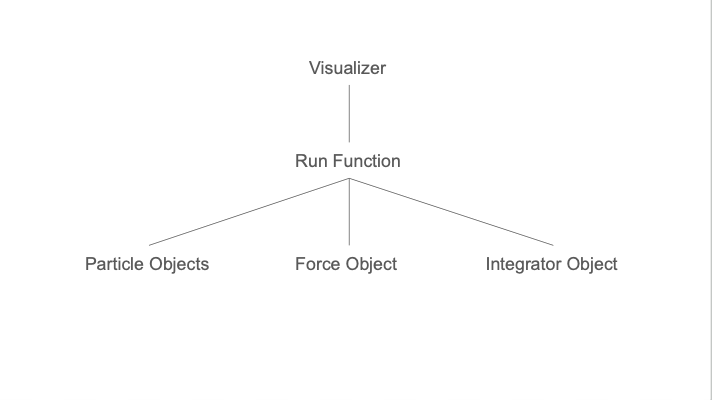

Import Libraries:

In [1]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import animation
from IPython.display import HTML

## Class Definitions

We will create three different classes: a Particle class for particle information, a Force class to calculate the force, and an Integrate class to integrate the given ODE

In [2]:
'''
Author: Constantine Moseley
Date: 2/15/2024

Particle class
Stores information about a particle: mass, charge, and position and
velocity at even time intervals
'''

class Particle:
    m = 0 #[kg]
    q = 0 #[C]

    ## Position & velocity stored in lists (timestep = time between entries)
    x = [] #[m]
    v = [] #[m/s]

    '''
    Constructor: Initializes a Particle object
    Inputs: x, v, m, q (all optional): set initial position, initial
                  velocity, mass, charge, respectively
    Returns: Nothing
    '''
    def __init__(self, x = (0,0), v = (0,0), m = 0, q = 0):
        self.x = [x]
        self.v = [v]
        self.m = m
        self.q = q

In [3]:
'''
Author: BW
Date: 2.15.23
Class:
    Calculates forces given a set of particles and their properties
'''

class Force:
    G = 0 #gravitation constant
    k = 0 #coloumb's constant

    #set G and k
    def __init__(self,Ge = 6.67408 * 10**-11,ke = 8.987 * 10**9):
        self.G = Ge
        self.k = ke

    '''Gravitation force
    inputs:
        m1: mass of particle one
        m2: mass of particle two
        x: x distance between particles
        y: y distance between particles
    returns:
        x_force: force in x direction
        y_force: force in y direction
    '''
    def gravity(self, m1, m2, x, y):
        G = 6.67408 * 10**-11
        r = np.sqrt(x**2+ y**2)
        try:
          force = -(self.G*m1*m2)/ r**2
        except Exception as e:
          print("Invalid gravitational force")
          return 0,0
        x_force = force*(x/r)
        y_force = force*(y/r)
        return x_force, y_force

    '''Electrical Force
    inputs:
        q1: charge of particle one
        q2: charge of particle two
        x: x distance between particles
        y: y distance between particles
    returns:
        x_force: force in x direction
        y_force: force in y direction
    '''
    def electro(self, q1, q2, x, y):
        k = 8.987 * 10**9
        r = np.sqrt(x**2+ y**2)
        try:
          force = (self.k*q1*q2)/ r**2
        except Exception as e:
          print("Invalid electric force")
          return 0,0
        x_force = force*(x/r)
        y_force = force*(y/r)
        return x_force, y_force

    '''Total Force
    inputs:
        m1: mass of particle one
        m2: mass of particle two
        q1: charge of particle one
        q2: charge of particle two
        x: x distance between particles
        y: y distance between particles
    returns:
        gx+ex: force in x direction
        gy+ey: force in y direction
    '''
    def totalforce(self,part1,part2):
        x = part1.x[-1][0]-part2.x[-1][0]
        y = part1.x[-1][1]-part2.x[-1][1]
        gx, gy = self.gravity(part1.m,part2.m,x,y)
        ex, ey = self.electro(part1.q,part2.q,x,y)
        return (gx+ex, gy+ey)

In [4]:
'''
'Author: Catelin Smith
'Date: 2/15/2024
'Integrator Class'

  Integrates the differential equation mx'' = -netforce to find the velocity
  and position functions for x and y directions

'''

class Integrate:

    '''
    constructor function
    inputs: particle: an object of the Particle class
            tot_force: the net force on the particle in the x direction, the net
                       force in the y direction
            frames: the number of frames
            timestep: the time between each frame
    '''

    def __init__(self, particle, tot_force, frames, timestep):
      self.curr_particle = particle
      self.force_val = tot_force

      # vp0 is in the form [position_x, position_y, velocity_x, velocity_y]
      self.vp0 = [self.curr_particle.x[-1][0], self.curr_particle.v[-1][0],
                  self.curr_particle.x[-1][1], self.curr_particle.v[-1][1]]

      self.t = np.linspace(0, timestep*frames, frames)

    '''
    function: velocity
    purpose: to produce an equation describing velocity in either x, y direction
    inputs: vp: the current position of the particle, the current velocity
                of the particle
            t: time we will be integrating over
            m: mass of the particle
            x_velocity: a boolean dictating if vp contains values pertaining
                        to x (true if yes, false if no -- if false, then vp's
                        values pertain to y)
    returns: a differential equation for velocity in the specified direction
    '''

    def velocity(self, vp, t, m, x_velocity):
        # set the x and y forces
        force_x,force_y = self.force_val

        # finds the x-velocity equation if the given values are for x; finds
        # the y-velocity equation if the values are for y
        if (x_velocity == True):
            x, vx = vp
            dxdt = [vx, force_x/m]
            return dxdt
        else:
            y, vy = vp
            dydt = [vy, force_y/m]
            return dydt


    '''
    function: ode_solver
    purpose: to solve the initial ODE ma = net-force for a given particle
    inputs: m: mass of the particle
    returns: sol_x: the position function for x, the velocity function for x
             sol_y: the position function for y, the velocity function for y
    '''

    def ode_solver(self, m):
        sol_x = odeint(self.velocity, self.vp0[0:2], self.t, args=(m,True))
        sol_y = odeint(self.velocity, self.vp0[2:], self.t, args=(m,False))
        return sol_x, sol_y

## Boundary Class

Creates a boundary object that checks if a particle has gone past a certain point. This particularly applies to simulations with particles in a box.

In [5]:
'''
Author: BW
Date: 2.15.23
Class:
    Creates a straight boundary
'''

class Boundary:
    coords = 0
    side = -1 #-1, negative side; +1, positive side
    axis = 0 #0, x-axis, 1,y axis

    def __init__(self, coords,side,axis):
      self.coords = coords
      self.side = side
      self.axis = axis

    def checkBound(self, particles):
      pos = [particles.x[0][0],  particles.x[0][1]]
      vel = [particles.v[0][0],  particles.v[0][1]]
      if (self.side)*pos[self.axis] > (self.side)*self.coords:
        pos[self.axis] = pos[self.axis]-(pos[self.axis]-self.coords)
        vel[self.axis] = -1*vel[self.axis]
      return pos,vel


## System Visualization

The following functions pertain to running and visualizing a given system using the classes defined above

In [6]:
'''
Author: Caroline Cromwell
Edited by: Constantine Moseley
Date: 2.29.23
'''

'''
Find range
Inputs: Index - takes 0 or 1 to compute x or y value, respectively
Returns: Bounds of range for graph
'''
def find_range(particles, index):
    # Adds every x or y value to list, computes top and bottom using max & min
    values = [particles[i].x[j][index] for i in range(len(particles)) for j in range(len(particles[0].x))]
    difference = max(values) - min(values)
    bottom = min(values) - difference/8
    top = max(values) + difference/8
    return((bottom, top))

'''
Visualize
Inputs: A list of particle objects, timestep, framerate, a boolean that is
        true if we want to display a line in our animation and false if not
Returns: Animation of particles over time
'''
def visualize(particles, timestep, framerate, create_line):
    # create a figure and axes
    fig, ax = plt.subplots(figsize=(12, 5))

    txt_title = ax.set_title('')
    ax.set_xlim(find_range(particles, 0))
    ax.set_ylim(find_range(particles, 1))
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title('Coordinate Plane')

    # create a color list (so that each particle has a different color)
    colors = ['g.', 'b.', 'r.', 'c.', 'm.', 'k.']

    # create list of objects that will change in the animation.
    points = [ax.plot([], [], colors[i % 6], ms=20)[0] for i in range(len(particles))]
    lines = [ax.plot([], [], colors[i % 6], lw=2)[0] for i in range(len(particles))]  # add lines for each particle

    # define function to give each particle a value for each frame
    def drawframe(n):
        for i in range(len(particles)):
            points[i].set_data([particles[i].x[n][0]], [particles[i].x[n][1]])
            # update / form a line if desired
            if ((n > 0) and (create_line == True)):
                lines[i].set_data([particles[i].x[k][0] for k in range(n + 1)], [particles[i].x[k][1] for k in range(n + 1)])
        # Rounds to the number of digits of timestep
        txt_title.set_text("Time: " + str(round(n * timestep, len(str(timestep)))) + " s")
        return lines  # return the lines to be updated in the animation

    # blit=True re-draws only the parts that have changed.
    anim = animation.FuncAnimation(fig, drawframe, frames=len(particles[0].x), interval=1000 / framerate, blit=True)

    # rendering animation
    return HTML(anim.to_html5_video())


In [7]:
'''
Run function
Inputs: A list of particles, the number of frames, the timestep between frames,
        a boolean that is true if we want to display a line in our animation
Returns: Animation of particles over time
'''
def run(particles, frames, timestep, framerate, create_line, bound = []):
    for k in range (frames-1): ## Frames - 1 because first frame is initial position
        f = Force()
        numParticles = len(particles)

        # Create a 2d list to store forces from each particle on each other particle
        forces = []
        for i in range(numParticles):
            row = []
            for j in range(numParticles):
                row.append((0, 0))
            forces.append(row)

        # Populate 2D force list by finding force from each particle on each other particle
        for i in range(numParticles):
            for j in range(numParticles):
                if i != j:
                  forces[i][j] = f.totalforce(particles[i], particles[j])

        # Calculate net force on each particle
        netForce = []
        for i in range(numParticles):
            x_force = [forces[i][j][0] for j in range(numParticles)]
            y_force = [forces[i][j][1] for j in range(numParticles)]
            netForce.append((np.sum(x_force), np.sum(y_force)))

        # Update positions & velocities of particles
        for i in range(numParticles):
            force_integrater = Integrate(particles[i], netForce[i], frames, timestep)
            v_pos_x, v_pos_y = force_integrater.ode_solver(particles[i].m)
            x1 =(v_pos_x[1, 0], v_pos_y[1 ,0])
            v1 =(v_pos_x[1, 1], v_pos_y[1, 1])
            for j in bound:
              x1, v1 = j.checkBound(Particle(x1,v1))

            particles[i].x.append(x1)
            particles[i].v.append(v1)


    # Use visualizer
    return visualize(particles, timestep, framerate, create_line)

## Possible Simulations

The following are examples of simulations one can run with our code:

#### Gravitational Five-Body System

This is an example of a five-body system with varying masses initially placed very close together -- they only experience gravitational force since they have no charge

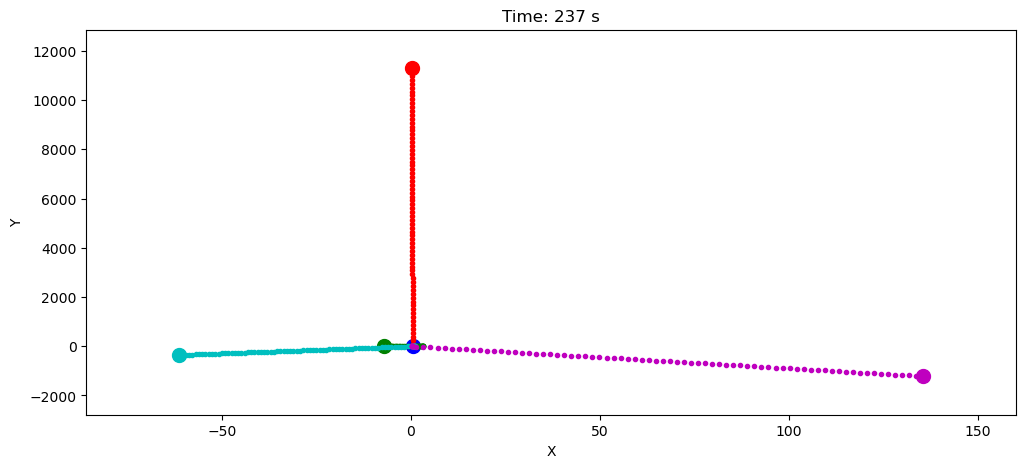

In [8]:
# 5 particles
particles = [Particle(x=(0.5, 2), v=(0.1,0), m = 1000, q = 0),
             Particle(x=(0.5, -2), m = 1000000000, q = 0),
             Particle(x=(0.5,0.75), m = 50000, q = 0),
             Particle(x=(1, 0.8), m = 1, q = 0),
             Particle(x=(0.2,0.5), m = 1, q = 0)]
run(particles, 80, 3, 20, True)


#### Orbits with a Gravitational Two-Body System

Here, we have two attempts at creating an orbit with lighter particle and a significantly heavier particle. They only experience gravitational force, and it is interesting to note that if the orbiting body does not begin with a large enough velocity, it will begin to escape the orbit.

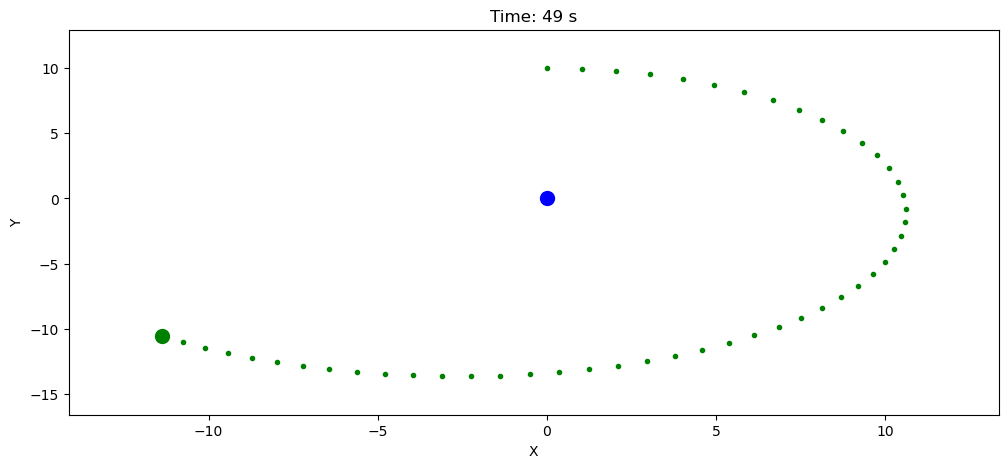

In [9]:
'''
Attempted circular orbit - solved by hand
Author: CM
3/3/24
'''

particles = [Particle(x=(0, 10), v=(1, 0), m = 10, q = 0),
             Particle(x=(0, 0), m = 1.498 * 10**11, q = 0)]
run(particles, 50, 1, 20, True)


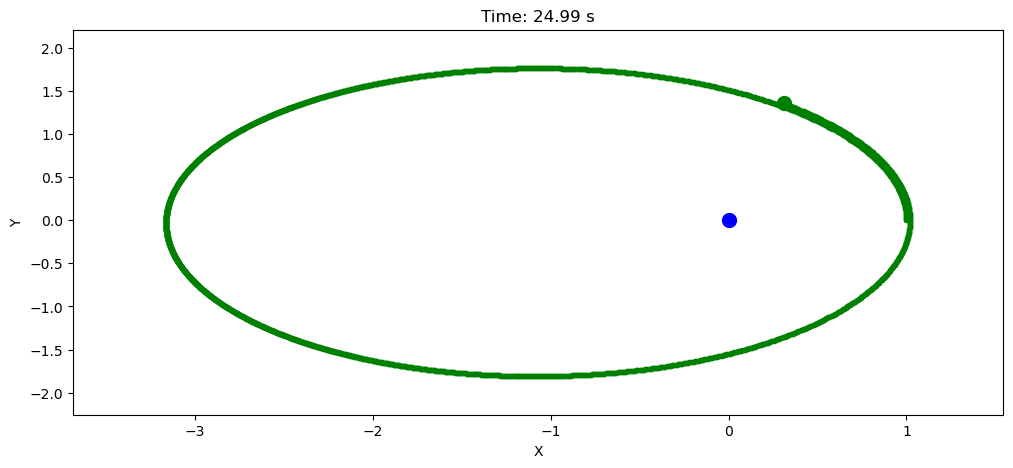

In [10]:
# an example of an eliptical orbit around a central mass
# author: CS

orbit_particles = [Particle(x=(1, 0), v=(0, 1), m = 1, q = 0),
             Particle(x=(0, 0), m = 9920000000, q = 0)]
run(orbit_particles, 2500, .01, 50, True)

#### Gravitational 361-Body Simulation of Equal-Mass Objects

The following simulation shows 361 particles of similarly large masses placed in a square configuration very close to each other. The simulation shows how the system will expand due to the large gravitational forces between the objects

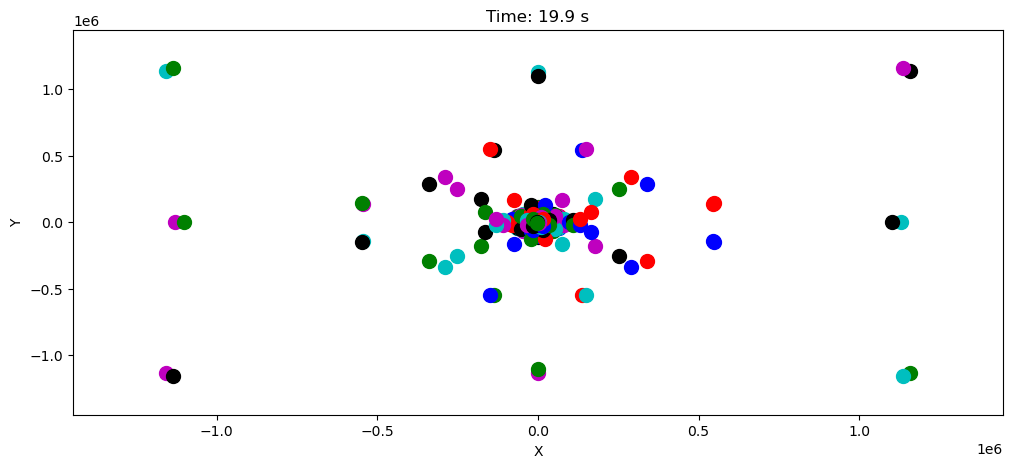

In [11]:
# example of 361 objects of equal mass expanding from a central location
# author: CS

expansion_particles = []

# size: half the length of the square configuration
size = 10

# will create particles of the same mass and velocity in different locations that are
# all 1 unit away from each other in a square
for i in range(size):
    for j in range(size):
        expansion_particles.append(Particle(x=(i,j), v =(0, 0), m = 5*(10**12), q = 0))
        if (j != 0):
            expansion_particles.append(Particle(x=(i,-j), v =(0, 0), m = 5*(10**12), q = 0))
        if (i != 0):
            expansion_particles.append(Particle(x=(-i,j), v =(0, 0), m = 5*(10**12), q = 0))
        if(i != 0 and j != 0):
            expansion_particles.append(Particle(x=(-i, -j),v =(0, 0), m = 5*(10**12), q = 0))

run(expansion_particles, 200, .1, 20, False)

#### An N-Body Simulation of Charged Particles in a Box

Using the boundary class, a simulation is created with five positively-charged particles trapped within a container

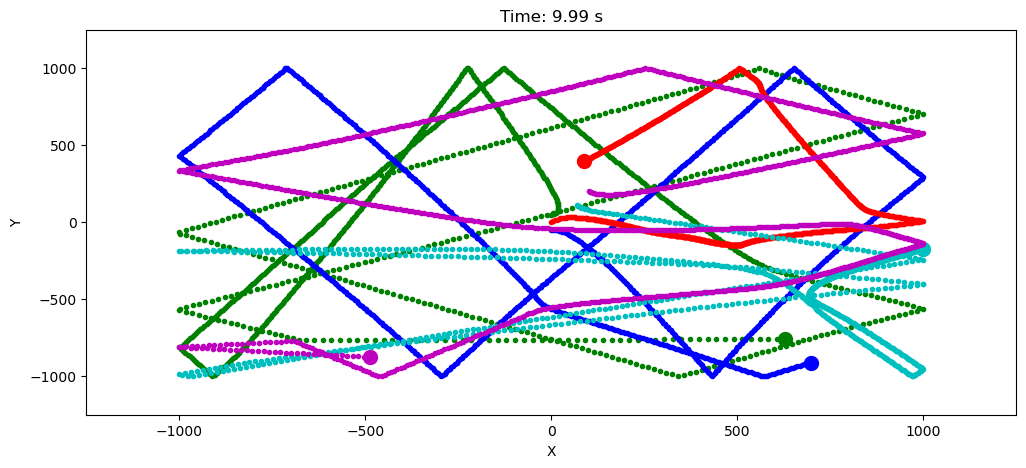

In [12]:
# Run simulation
particles = [Particle(x=(0,50), v=(400,100), m = 400, q = 1),
             Particle(x=(0,-50), v=(500,100), m = 400, q = 1),
             Particle(x=(0,0), v=(500,600), m = 500, q = 1),
             Particle(x=(70, 109),v=(300,-500), m = 300, q = 1),
             Particle(x=(100,202),v=(360,-400), m = 400, q = 1)]
bounds = [Boundary(1000,1,0),Boundary(1000,1,1),Boundary(-1000,-1,0),Boundary(-1000,-1,1)]
run(particles, 1000, 0.01, 100, True, bounds)


Below is a simulation created with 100 positively-charged particles trapped within a container

In [ ]:
# Run simulation
expansion_particles = []
size = 10
for i in range(size):
    for j in range(size):
        expansion_particles.append(Particle(x=(100*i,100*j), v =(0, 0), m = 100, q = 1))
bounds = [Boundary(1000,1,0),Boundary(1000,1,1),Boundary(-1000,-1,0),Boundary(-1000,-1,1)]
run(expansion_particles, 10000, 0.0001, 1000, False, bounds)
